# Laboratorio 12: Memorias asociativas con redes de Hopfield

**Mateo Caballero** - Aprendizaje Estadístico - semestre 2026-2

Enunciado original: `semestre2026-2/Laboratorios/Laboratorio_12_Lab_Hopfield.ipynb`

Se conserva el notebook del enunciado en su orden y debajo va el desarrollo:

- Las siete funciones pedidas (puntos 1 a 7), cada una con una comprobación.
- Las siete preguntas guía, respondidas con experimentos.
- Una verificación numérica de la capacidad $P_c\approx0.138N$.

El código del enunciado se ejecuta sin cambios. Las celdas propias empiezan con `# [Añadido]`. Se omiten dos
celdas vacías y el botón "Open in Colab", que abre el notebook original del profesor. Hace falta NumPy 2
(por `np.concat`) y scikit-image (por las imágenes de prueba).

# Laboratorio: Memorias asociativas con redes de Hopfield

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.

---

# Preguntas guía

1. ¿La energía disminuye durante la recuperación?
2. ¿La red recupera exactamente la imagen original?
3. ¿Qué ocurre si aumenta el nivel de ruido?
4. ¿Qué pasa si se almacenan varias imágenes?
5. ¿Aparecen estados espurios?
6. ¿La recuperación depende del orden en que se actualizan los píxeles?
7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.




## Datos del enunciado

Hay dos ejemplos: tres patrones sintéticos de $10\times10$ (horizontal, vertical y ajedrez) y la imagen
`camera` reducida a $64\times64$ y binarizada.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def patrones_balanceados(n, m):
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1

    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1

    checker = np.indices((n, m)).sum(axis=0)
    checker = np.where(checker % 2 == 0, 1, -1)

    return horizontal, vertical, checker

def agregar_ruido(s, frac=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

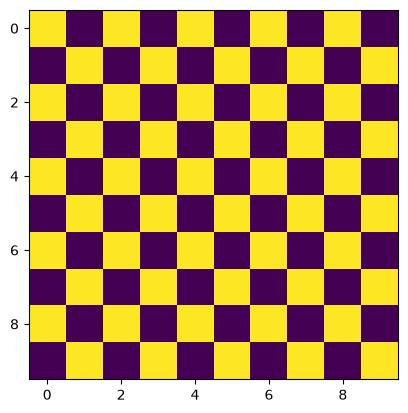

In [3]:
h, v, d = patrones_balanceados(10, 10)
plt.imshow(d)

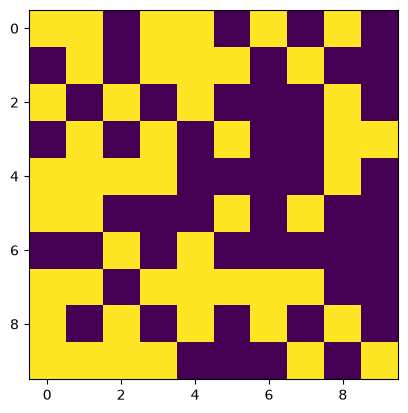

In [4]:
s_ruido = agregar_ruido(np.concat(d), frac=0.25, seed=10)
plt.imshow(np.reshape(s_ruido, (10, 10)))

In [5]:
# [Añadido]
# Se guardan los tres patrones de 10x10 y se revisa qué tan parecidos son entre sí
NOMBRES_10 = ["horizontal", "vertical", "ajedrez"]
P10 = np.array([p.ravel() for p in (h, v, d)])
print("Suma de cada patrón:", P10.sum(axis=1))
print("Solapamientos (1/N) xi_mu . xi_nu:")
print(P10 @ P10.T / P10.shape[1])

Suma de cada patrón: [0. 0. 0.]
Solapamientos (1/N) xi_mu . xi_nu:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


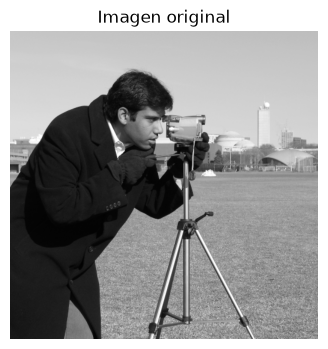

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

img = data.camera()   # imagen 512x512 en escala de grises

plt.figure(figsize=(4,4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

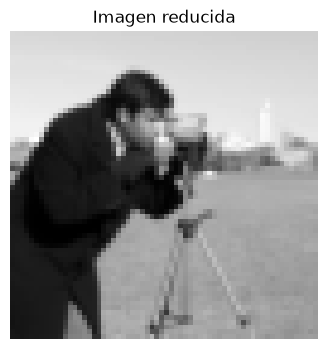

In [7]:
# ============================================================
# Reducir imagen
# ============================================================

n = 64
m = 64

img_small = resize(img, (n, m), anti_aliasing=True)

plt.figure(figsize=(4,4))
plt.imshow(img_small, cmap="gray")
plt.title("Imagen reducida")
plt.axis("off")
plt.show()

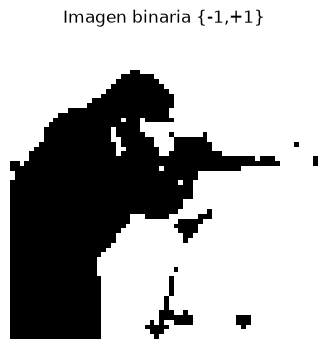

In [8]:
# ============================================================
# Binarización
# ============================================================

threshold = img_small.mean()

img_bin = np.where(img_small > threshold, 1, -1)

plt.figure(figsize=(4,4))
plt.imshow(img_bin, cmap="gray")
plt.title("Imagen binaria {-1,+1}")
plt.axis("off")
plt.show()

In [9]:
img_bin

array([[ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       ...,
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1]], shape=(64, 64))

In [10]:
# ============================================================
# Ruido
# ============================================================

def agregar_ruido(s, frac=0.30, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido


frac_ruido = 0.30

s_ruido = agregar_ruido(np.concat(img_bin), frac=frac_ruido, seed=123)


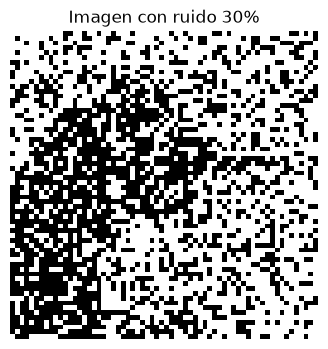

In [11]:
plt.figure(figsize=(4,4))
plt.imshow(s_ruido.reshape(n, m), cmap="gray")
plt.title(f"Imagen con ruido {frac_ruido*100:.0f}%")
plt.axis("off")
plt.show()

In [12]:
# [Añadido]
print("img_bin:", img_bin.shape, "| valores:", np.unique(img_bin))
print(f"umbral (media) = {threshold:.4f} | píxeles +1: {np.mean(img_bin == 1):.1%}")
print(f"píxeles cambiados por el ruido: {np.sum(s_ruido != img_bin.ravel())} de {img_bin.size}")

img_bin: (64, 64) | valores: [-1  1]
umbral (media) = 0.5061 | píxeles +1: 65.3%
píxeles cambiados por el ruido: 1228 de 4096


**Observaciones sobre los datos.**

- Los tres patrones de $10\times10$ suman cero y son ortogonales entre sí, con solapamiento 0. Para la
  regla de Hebb es el caso favorable, porque un patrón no interfiere con los otros cuando la red está
  exactamente en él.
- `camera` no está balanceada: con el umbral en la media (0.5061), el 65.3 % de los píxeles queda en $+1$.
- El enunciado define `agregar_ruido` dos veces y solo cambia el valor por defecto de `frac`, de 0.25 a
  0.30. Queda vigente la segunda. En el desarrollo se pasa `frac` siempre de forma explícita.

# Desarrollo

Notación: $q=\xi\cdot s$ es el producto entre un patrón y el estado, y $m=q/N$ es el solapamiento. Vale 1
si el estado es el patrón, $-1$ si es su negativo y 0 si coinciden en la mitad de los píxeles. Si se
invierte una fracción $p$ de los píxeles, $m=1-2p$.

### Punto 1. Imagen a vector de estados

> 1. Convertir una imagen binaria en un vector de estados.

La imagen se aplana por filas. La función rechaza valores distintos de $\pm1$: una imagen en 0 y 1 daría
una matriz de Hebb equivocada sin producir ningún error.

In [13]:
# [Añadido]
SEED = 42
TOL = 1e-10      # un campo con |h| <= TOL se trata como cero


def imagen_a_vector(imagen):
    """Aplana una imagen binaria {-1, +1} por filas y devuelve un vector de N estados."""
    imagen = np.asarray(imagen)
    if not np.isin(imagen, (-1, 1)).all():
        raise ValueError("La imagen debe contener solo -1 y +1")
    return imagen.astype(float).ravel()


def vector_a_imagen(s, forma):
    return np.reshape(s, forma)


xi = imagen_a_vector(img_bin)
print("vector:", xi.shape)
print("¿se recupera la misma imagen al deshacer?", np.array_equal(vector_a_imagen(xi, (n, m)), img_bin))

vector: (4096,)
¿se recupera la misma imagen al deshacer? True


### Punto 2. Matriz de pesos

> 2. Calcular la matriz de pesos de Hopfield.

Si $X$ tiene un patrón por fila, la suma de Hebb es $W=X^TX/N$, y después se anula la diagonal. Se compara
con la suma escrita término a término.

In [14]:
# [Añadido]
def matriz_pesos(patrones):
    """Regla de Hebb con diagonal nula. patrones tiene una fila por patrón."""
    X = np.atleast_2d(patrones).astype(float)
    W = X.T @ X / X.shape[1]
    np.fill_diagonal(W, 0.0)
    return W


# Comprobación contra la suma de la definición, escrita con bucles
W10 = matriz_pesos(P10)
N10 = P10.shape[1]
W_bucles = np.array([[0.0 if i == j else sum(p[i] * p[j] for p in P10) / N10
                      for j in range(N10)] for i in range(N10)])
print("10x10: forma", W10.shape, "| diferencia máxima con los bucles:", np.abs(W10 - W_bucles).max())
print("simétrica:", np.array_equal(W10, W10.T), "| diagonal nula:", not W10.diagonal().any())

W_cam = matriz_pesos(xi)
print("camera 64x64: forma", W_cam.shape, f"| memoria = {W_cam.nbytes / 2**20:.0f} MiB")

10x10: forma (100, 100) | diferencia máxima con los bucles: 0.0
simétrica: True | diagonal nula: True
camera 64x64: forma (4096, 4096) | memoria = 128 MiB


### Punto 3. Campo local

> 3. Calcular el campo local que siente una neurona.

$h_i$ es el producto de la fila $i$ de $W$ por el estado actual.

In [15]:
# [Añadido]
def campo_local(W, s, i):
    """h_i = suma_j w_ij s_j, con el estado que tenga s en este momento."""
    return W[i] @ s


rng = np.random.default_rng(SEED)
s_prueba = rng.choice([-1.0, 1.0], N10)
error = max(abs(campo_local(W10, s_prueba, i) - sum(W10[i, j] * s_prueba[j] for j in range(N10)))
            for i in range(N10))
print(f"diferencia máxima con la suma explícita: {error:.1e}")

diferencia máxima con la suma explícita: 1.1e-16


### Punto 4. Actualización de una neurona

> 4. Actualizar el estado de una neurona.

El enunciado no define qué hacer si $h_i=0$. Aquí la neurona conserva su estado, porque `np.sign(0)`
devolvería 0, que no es un estado válido. El cero se compara con una tolerancia de $10^{-10}$, ya que
$1/N$ no siempre es exacto en punto flotante.

Cuando solo cambia $s_i$, y como $W$ es simétrica con diagonal nula,

$$\Delta E=-(s_i^{\rm nuevo}-s_i)\,h_i .$$

Así se conoce la energía después de cada paso sin recalcular $s^TWs$.

In [16]:
# [Añadido]
def actualizar_neurona(W, s, i):
    """Aplica s_i <- sign(h_i) sobre el mismo vector s y devuelve el cambio de energía."""
    h_i = campo_local(W, s, i)
    if abs(h_i) <= TOL:
        return 0.0                  # empate: la neurona conserva su estado
    nuevo = 1.0 if h_i > 0 else -1.0
    if nuevo == s[i]:
        return 0.0
    dE = -(nuevo - s[i]) * h_i
    s[i] = nuevo
    return dE


# Tres neuronas con campo positivo, negativo y nulo
W_mini = np.array([[0, 1, 0], [1, 0, 0], [0, 0, 0]], dtype=float)
for s_ini, i in (([-1, 1, 1], 0), ([1, -1, 1], 0), ([1, 1, -1], 2)):
    s = np.array(s_ini, dtype=float)
    h_i = campo_local(W_mini, s, i)
    dE = actualizar_neurona(W_mini, s, i)
    print(f"h = {h_i:+.0f}: s_i pasa de {s_ini[i]:+d} a {int(s[i]):+d}, dE = {dE:+.0f}")

h = +1: s_i pasa de -1 a +1, dE = -2
h = -1: s_i pasa de +1 a -1, dE = -2
h = +0: s_i pasa de -1 a -1, dE = +0


### Punto 5. Energía total

> 5. Calcular la energía total de la red.

Además de implementar la fórmula se comprueba la expresión de $\Delta E$ del punto anterior. Con un solo
patrón la energía tiene forma cerrada,

$$E=-\frac{1}{2N}\left(q^2-N\right)=-\frac{Nm^2-1}{2},$$

que en el patrón ($m=1$) vale $-(N-1)/2$.

In [17]:
# [Añadido]
def energia(W, s):
    return -0.5 * (s @ W @ s)


# El dE de actualizar_neurona debe ser igual a la resta de las dos energías completas
rng = np.random.default_rng(SEED)
error, cambios = 0.0, 0
for _ in range(50):
    s = rng.choice([-1.0, 1.0], N10)
    for i in rng.permutation(N10):
        antes = energia(W10, s)
        dE = actualizar_neurona(W10, s, i)
        error = max(error, abs(energia(W10, s) - antes - dE))
        cambios += dE != 0
print(f"{cambios} cambios de estado | máximo |dE - (E_despues - E_antes)| = {error:.1e}")

N = xi.size
print(f"energía de la imagen original = {energia(W_cam, xi)} | -(N-1)/2 = {-(N - 1) / 2}")

2167 cambios de estado | máximo |dE - (E_despues - E_antes)| = 3.1e-14
energía de la imagen original = -2047.5 | -(N-1)/2 = -2047.5


### Punto 6. Ruido

> 6. Aplicar ruido a una imagen.

Se usa `agregar_ruido` del enunciado. Invierte exactamente `int(frac*N)` píxeles distintos, así que no es
ruido independiente por píxel: el número de errores es fijo.

In [18]:
# [Añadido]
for frac in (0.0, 0.10, 0.30, 0.50, 1.0):
    ruidosa = agregar_ruido(xi, frac=frac, seed=SEED)
    print(f"frac = {frac:.2f}: pedidos {int(frac * N):4d}, cambiados {np.sum(ruidosa != xi):4d}")

print("la imagen original no se modifica:", np.array_equal(xi, imagen_a_vector(img_bin)))
print("misma semilla, mismo ruido:",
      np.array_equal(agregar_ruido(xi, 0.3, SEED), agregar_ruido(xi, 0.3, SEED)))

frac = 0.00: pedidos    0, cambiados    0
frac = 0.10: pedidos  409, cambiados  409
frac = 0.30: pedidos 1228, cambiados 1228
frac = 0.50: pedidos 2048, cambiados 2048
frac = 1.00: pedidos 4096, cambiados 4096
la imagen original no se modifica: True
misma semilla, mismo ruido: True


### Punto 7. Recuperación asincrónica aleatoria

> 7. Recuperar la imagen mediante actualización asincrónica aleatoria.

Se sigue el algoritmo sugerido con una precisión: los píxeles se eligen por barridos, cada uno con una
permutación aleatoria nueva. Así todos se visitan, y un barrido sin cambios garantiza que el estado es un
punto fijo. Cada campo se calcula con la imagen ya actualizada.

In [19]:
# [Añadido]
def recuperar(W, s0, rng, max_barridos=100, instantes=()):
    """Actualización asincrónica aleatoria.

    Cada barrido visita las N neuronas una vez, en un orden al azar. Termina cuando un barrido
    completo no cambia ningún píxel o cuando se llega a max_barridos.
    """
    s = np.array(s0, dtype=float)
    E = [energia(W, s)]
    fotos, cambios, t = {}, [], 0
    for barrido in range(1, max_barridos + 1):
        n_cambios = 0
        for i in rng.permutation(len(s)):
            if t in instantes:
                fotos[t] = s.copy()
            dE = actualizar_neurona(W, s, i)
            E.append(E[-1] + dE)
            n_cambios += int(dE != 0)
            t += 1
        cambios.append(n_cambios)
        if n_cambios == 0:
            break
    return {"s": s, "E": np.array(E), "cambios": cambios, "barridos": barrido,
            "convergio": cambios[-1] == 0, "fotos": fotos}


s0 = imagen_a_vector(s_ruido.reshape(n, m))
res = recuperar(W_cam, s0, np.random.default_rng(SEED), instantes=(0, 512, 1024, 2048, 3072))
print("convergió:", res["convergio"], "| barridos:", res["barridos"], "| cambios por barrido:", res["cambios"])
print("píxeles errados:", np.sum(s0 != xi), "->", np.sum(res["s"] != xi))

convergió: True | barridos: 2 | cambios por barrido: [1228, 0]
píxeles errados: 1228 -> 0


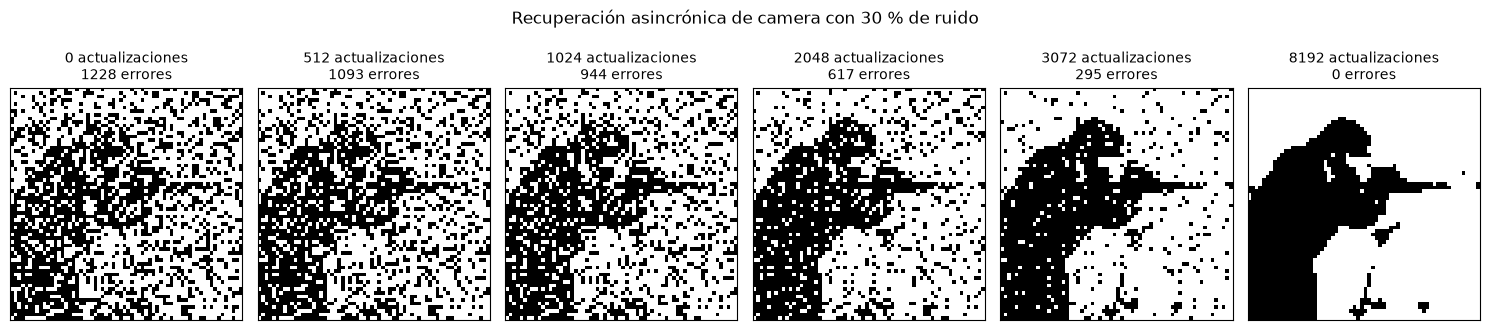

In [20]:
# [Añadido]
def mostrar(ax, s, forma, titulo=""):
    ax.imshow(np.reshape(s, forma), cmap="gray", vmin=-1, vmax=1, interpolation="nearest")
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([])       # se deja el marco: los bordes blancos se perderían contra el fondo
    ax.set_yticks([])


cuadros = list(res["fotos"].items()) + [(len(res["E"]) - 1, res["s"])]
fig, axes = plt.subplots(1, len(cuadros), figsize=(15, 3.7))
for ax, (t, s) in zip(axes, cuadros):
    mostrar(ax, s, (n, m), f"{t} actualizaciones\n{np.sum(s != xi)} errores")
plt.suptitle("Recuperación asincrónica de camera con 30 % de ruido")
plt.tight_layout()
plt.show()

La red corrige los 1 228 píxeles invertidos en el primer barrido. El segundo no cambia nada y solo
confirma la convergencia. En la secuencia los errores bajan de manera gradual porque cada píxel errado se
arregla la primera vez que se visita.

# Preguntas guía

### Pregunta 1

> 1. ¿La energía disminuye durante la recuperación?

E inicial = -327.820 | teoría -(N m0^2 - 1)/2 con m0 = 0.4004: -327.820
E final   = -2047.500 | recalculada al final: -2047.500
actualizaciones en total: 8192
pasos que bajan: 1228 | iguales: 6964 | suben: 0


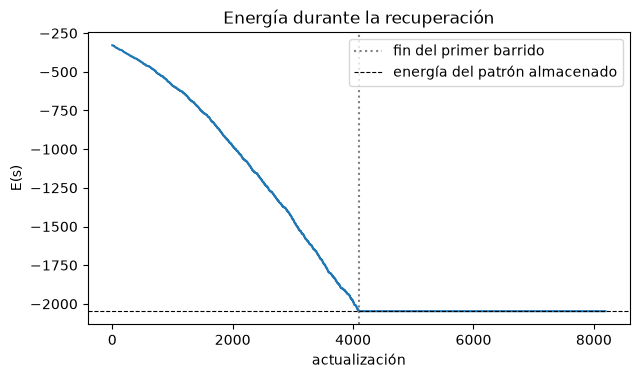

In [21]:
# [Añadido]
E = res["E"]
pasos = np.diff(E)
m0 = s0 @ xi / N
print(f"E inicial = {E[0]:.3f} | teoría -(N m0^2 - 1)/2 con m0 = {m0:.4f}: {-(N * m0**2 - 1) / 2:.3f}")
print(f"E final   = {E[-1]:.3f} | recalculada al final: {energia(W_cam, res['s']):.3f}")
print(f"actualizaciones en total: {len(pasos)}")
print(f"pasos que bajan: {np.sum(pasos < 0)} | iguales: {np.sum(pasos == 0)} | suben: {np.sum(pasos > 0)}")

plt.figure(figsize=(7, 3.8))
plt.plot(E)
plt.axvline(N, color="gray", ls=":", label="fin del primer barrido")
plt.axhline(-(N - 1) / 2, color="k", ls="--", lw=0.8, label="energía del patrón almacenado")
plt.xlabel("actualización")
plt.ylabel("E(s)")
plt.title("Energía durante la recuperación")
plt.legend()
plt.show()

**Sí, y nunca sube.** De las 8 192 actualizaciones, 1 228 bajan la energía (una por píxel corregido) y
6 964 la dejan igual. La energía pasa de $-327.820$ a $-2047.5$, los dos valores que predice la fórmula
del punto 5.

La razón está en $\Delta E=-(s_i^{\rm nuevo}-s_i)h_i$. Si la neurona cambia es porque $h_i$ tiene el signo
de $s_i^{\rm nuevo}$, de modo que $\Delta E=-2|h_i|<0$. Como hay un número finito de estados, la dinámica
asincrónica tiene que detenerse en un mínimo local.

### Pregunta 2

> 2. ¿La red recupera exactamente la imagen original?

In [22]:
# [Añadido]
rng = np.random.default_rng(SEED)
exactas, barridos = 0, []
for k in range(100):
    r = recuperar(W_cam, agregar_ruido(xi, 0.30, seed=k), rng)
    exactas += np.array_equal(r["s"], xi)
    barridos.append(r["barridos"])
print(f"camera, 30 % de ruido: {exactas}/100 recuperaciones exactas | barridos usados: {sorted(set(barridos))}")

# El ejemplo de ajedrez del enunciado (25 %, seed=10), con una red que solo guarda ese patrón
xi_d = imagen_a_vector(d)
ruidosa_d = agregar_ruido(xi_d, frac=0.25, seed=10)
r_d = recuperar(matriz_pesos(xi_d), ruidosa_d, np.random.default_rng(SEED))
print(f"ajedrez, 25 % de ruido: {np.sum(ruidosa_d != xi_d)} -> {np.sum(r_d['s'] != xi_d)} errores")

camera, 30 % de ruido: 100/100 recuperaciones exactas | barridos usados: [2]
ajedrez, 25 % de ruido: 25 -> 0 errores


**Con un patrón almacenado y 30 % de ruido, sí.** Las 100 repeticiones con `camera` terminan sin un solo
píxel errado, todas en dos barridos. El tablero del enunciado pasa de 25 errores a 0.

Con un solo patrón el campo es

$$h_i=\frac{\xi_i\,q-s_i}{N}.$$

Si $q>1$, su signo es el de $\xi_i$ en todos los píxeles, sin importar cuánto valga $s_i$. Con 30 % de
ruido en `camera`, $m=0.4004$ y por lo tanto $q$ está muy por encima de 1. Con varios patrones esto deja
de estar garantizado (pregunta 4).

### Pregunta 3

> 3. ¿Qué ocurre si aumenta el nivel de ruido?

 ruido   original  negativo  otro
  0.10       100         0     0
  0.30       100         0     0
  0.40       100         0     0
  0.45       100         0     0
  0.48       100         0     0
  0.49       100         0     0
  0.50        35        65     0
  0.51         0       100     0
  0.52         0       100     0
  0.55         0       100     0
  0.70         0       100     0
  1.00         0       100     0


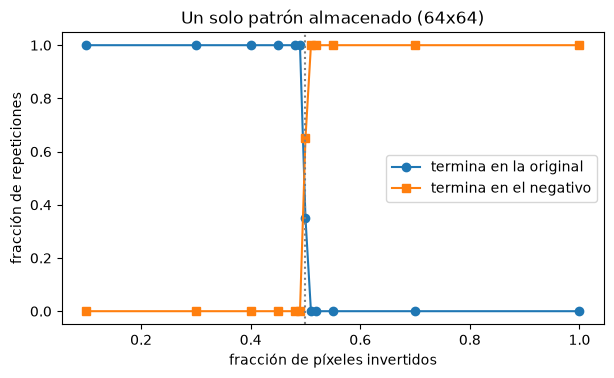

In [23]:
# [Añadido]
niveles = [0.10, 0.30, 0.40, 0.45, 0.48, 0.49, 0.50, 0.51, 0.52, 0.55, 0.70, 1.00]
REP = 100
rng = np.random.default_rng(SEED)
tasas = []
print(" ruido   original  negativo  otro")
for j, p in enumerate(niveles):
    cuenta = np.zeros(3, dtype=int)
    for k in range(REP):
        s = recuperar(W_cam, agregar_ruido(xi, p, seed=1000 * j + k), rng)["s"]
        cuenta[0 if np.array_equal(s, xi) else 1 if np.array_equal(s, -xi) else 2] += 1
    tasas.append(cuenta / REP)
    print(f"{p:6.2f} {cuenta[0]:9d} {cuenta[1]:9d} {cuenta[2]:5d}")

tasas = np.array(tasas)
plt.figure(figsize=(7, 3.8))
plt.plot(niveles, tasas[:, 0], "o-", label="termina en la original")
plt.plot(niveles, tasas[:, 1], "s-", label="termina en el negativo")
plt.axvline(0.5, color="gray", ls=":")
plt.xlabel("fracción de píxeles invertidos")
plt.ylabel("fracción de repeticiones")
plt.title("Un solo patrón almacenado (64x64)")
plt.legend()
plt.show()

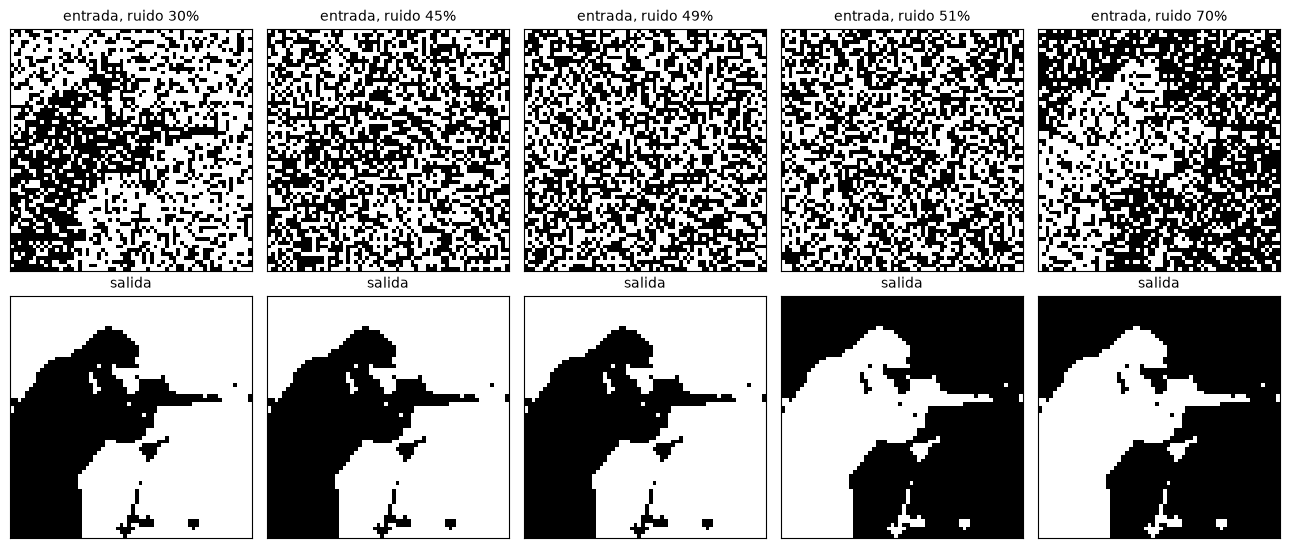

In [24]:
# [Añadido]
ejemplos = [0.30, 0.45, 0.49, 0.51, 0.70]
fig, axes = plt.subplots(2, len(ejemplos), figsize=(13, 5.6))
rng = np.random.default_rng(SEED)
for k, p in enumerate(ejemplos):
    entrada = agregar_ruido(xi, p, seed=k)
    mostrar(axes[0, k], entrada, (n, m), f"entrada, ruido {p:.0%}")
    mostrar(axes[1, k], recuperar(W_cam, entrada, rng)["s"], (n, m), "salida")
plt.tight_layout()
plt.show()

In [25]:
# [Añadido]
# En el 50 % exacto, ¿quién decide? La primera neurona que se visita
W_d = matriz_pesos(xi_d)
for nombre, W, obj, reps in (("ajedrez 10x10", W_d, xi_d, 4000), ("camera 64x64", W_cam, xi, 500)):
    al_original, predichas = 0, 0
    for k in range(reps):
        inicio = agregar_ruido(obj, 0.5, seed=k)
        primera = np.random.default_rng(k).permutation(len(obj))[0]
        llega = np.array_equal(recuperar(W, inicio, np.random.default_rng(k))["s"], obj)
        al_original += llega
        predichas += llega == (inicio[primera] != obj[primera])
    print(f"{nombre}, 50 % exacto, {reps} repeticiones: original {al_original / reps:.1%} | "
          f"lo predice la primera neurona visitada: {predichas}/{reps}")

rng = np.random.default_rng(SEED)
ok = sum(np.array_equal(recuperar(W_d, agregar_ruido(xi_d, 0.49, seed=k), rng)["s"], xi_d) for k in range(1000))
print(f"ajedrez con 49 píxeles errados de 100: {ok}/1000 recuperaciones exactas")

ajedrez 10x10, 50 % exacto, 4000 repeticiones: original 49.8% | lo predice la primera neurona visitada: 4000/4000
camera 64x64, 50 % exacto, 500 repeticiones: original 47.4% | lo predice la primera neurona visitada: 500/500
ajedrez con 49 píxeles errados de 100: 1000/1000 recuperaciones exactas


**Con un patrón no hay deterioro gradual: hay un salto en el 50 %.**

- Hasta 49 % la recuperación es exacta en las 100 repeticiones de cada nivel, aunque a esa altura la
  entrada ya no se reconoce a simple vista. En $10\times10$, 49 errores de 100 también se corrigen
  siempre (1 000 de 1 000), y ahí $q$ vale apenas 2.
- Desde 51 % termina siempre en el negativo. Como $E(s)=E(-s)$, $-\xi$ es una memoria igual de buena que
  $\xi$, y la entrada ya se parece más a ella.
- En el 50 % exacto $q=0$ y $h_i=-s_i/N$: la primera neurona visitada cambia con seguridad y rompe el
  empate. Si estaba mal queda $q=2$ y se llega a la original. Si estaba bien, al negativo. Esa regla
  acertó en las 4 000 repeticiones del tablero y en las 500 de `camera`. Por eso la probabilidad es 1/2
  (49.8 % y 47.4 % medidos), y el 35/65 de la tabla con 100 repeticiones es una fluctuación de muestreo.

### Pregunta 4

> 4. ¿Qué pasa si se almacenan varias imágenes?

Primero se usan los patrones ortogonales de $10\times10$ y después imágenes reales.

P = 1: 0.05->100.0%  0.10->100.0%  0.15->100.0%  0.20->100.0%  0.25->100.0%  0.30->100.0%  0.35->100.0%  0.40->100.0%  0.45->100.0%
P = 2: 0.05->100.0%  0.10->100.0%  0.15->100.0%  0.20->100.0%  0.25->100.0%  0.30->100.0%  0.35->100.0%  0.40->95.8%  0.45->65.2%
P = 3: 0.05->100.0%  0.10->100.0%  0.15->100.0%  0.20->100.0%  0.25->100.0%  0.30->100.0%  0.35->94.8%  0.40->77.3%  0.45->32.2%


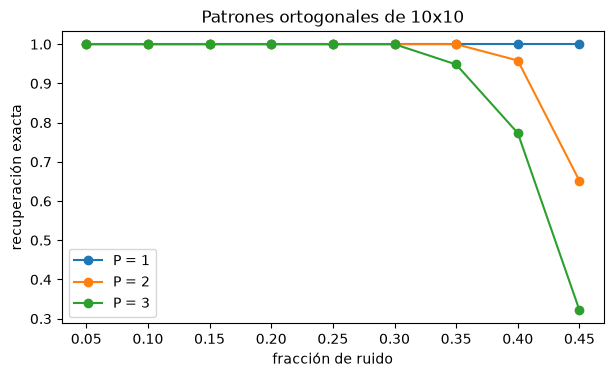

In [26]:
# [Añadido]
niveles_10 = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45]
REP_10 = 600
curvas = {}
rng = np.random.default_rng(SEED)
for P in (1, 2, 3):
    W = matriz_pesos(P10[:P])
    curvas[P] = []
    for j, p in enumerate(niveles_10):
        ok = 0
        for k in range(REP_10):
            obj = P10[k % P]
            ok += np.array_equal(recuperar(W, agregar_ruido(obj, p, seed=1000 * j + k), rng)["s"], obj)
        curvas[P].append(ok / REP_10)
    print(f"P = {P}:", "  ".join(f"{p:.2f}->{t:.1%}" for p, t in zip(niveles_10, curvas[P])))

plt.figure(figsize=(7, 3.8))
for P, t in curvas.items():
    plt.plot(niveles_10, t, "o-", label=f"P = {P}")
plt.xlabel("fracción de ruido")
plt.ylabel("recuperación exacta")
plt.title("Patrones ortogonales de 10x10")
plt.legend()
plt.show()

Ahora se guardan hasta seis imágenes de scikit-image. Se comparan con dos controles del mismo tamaño: las
mismas imágenes binarizadas con la mediana (quita el desbalance entre $+1$ y $-1$) y patrones aleatorios
(quitan además la estructura de las imágenes). Una memoria es estable si ningún píxel cambia al arrancar
la red justo en ella.

In [27]:
# [Añadido]
NOMBRES_IMG = ["camera", "astronaut", "coins", "coffee", "rocket", "chelsea"]


def reducir(imagen):
    gris = rgb2gray(imagen) if imagen.ndim == 3 else imagen
    return resize(gris, (n, m), anti_aliasing=True)


grises = [reducir(getattr(data, nombre)()) for nombre in NOMBRES_IMG]
conjuntos = {
    "umbral media": np.array([np.where(g > g.mean(), 1.0, -1.0).ravel() for g in grises]),
    "umbral mediana": np.array([np.where(g > np.median(g), 1.0, -1.0).ravel() for g in grises]),
    "aleatorios": np.random.default_rng(SEED).choice([-1.0, 1.0], (len(grises), n * m)),
}
assert np.array_equal(conjuntos["umbral media"][0], xi)     # la primera es la imagen del enunciado

rng = np.random.default_rng(SEED)
print(f"{'patrones':15s} {'P':>2} {'máx |solap.|':>13} {'estables':>9} {'exactas':>9} {'píxeles bien':>13}")
finales = {}
for nombre, todos in conjuntos.items():
    for P in range(1, len(todos) + 1):
        X = todos[:P]
        W = matriz_pesos(X)
        campos = X @ W                       # fila mu: campo en el patrón mu
        estables = sum(np.all((np.abs(c) <= TOL) | (np.sign(c) == x)) for c, x in zip(campos, X))
        exactas, bien, salidas = 0, [], []
        for k, x in enumerate(X):
            for r in range(5):               # 5 ruidos distintos por imagen
                s = recuperar(W, agregar_ruido(x, 0.30, seed=100 * k + r), rng)["s"]
                exactas += np.array_equal(s, x)
                bien.append(np.mean(s == x))
                if r == 0:
                    salidas.append(s)
        solap = np.abs(X @ X.T / X.shape[1] - np.eye(P)).max()
        print(f"{nombre:15s} {P:2d} {solap:13.3f} {f'{estables}/{P}':>9} "
              f"{f'{exactas}/{5 * P}':>9} {np.mean(bien):13.1%}")
    finales[nombre] = salidas

patrones         P  máx |solap.|  estables   exactas  píxeles bien
umbral media     1         0.000       1/1       5/5        100.0%
umbral media     2         0.016       2/2     10/10        100.0%
umbral media     3         0.097       3/3     15/15        100.0%
umbral media     4         0.179       4/4     20/20        100.0%
umbral media     5         0.460       4/5     20/25         99.9%
umbral media     6         0.460       5/6     25/30         99.9%
umbral mediana   1         0.000       1/1       5/5        100.0%
umbral mediana   2         0.156       2/2     10/10        100.0%
umbral mediana   3         0.170       3/3     15/15        100.0%
umbral mediana   4         0.201       4/4     20/20        100.0%
umbral mediana   5         0.459       4/5     19/25         99.2%
umbral mediana   6         0.459       5/6     24/30         98.5%
aleatorios       1         0.000       1/1       5/5        100.0%
aleatorios       2         0.009       2/2     10/10        10

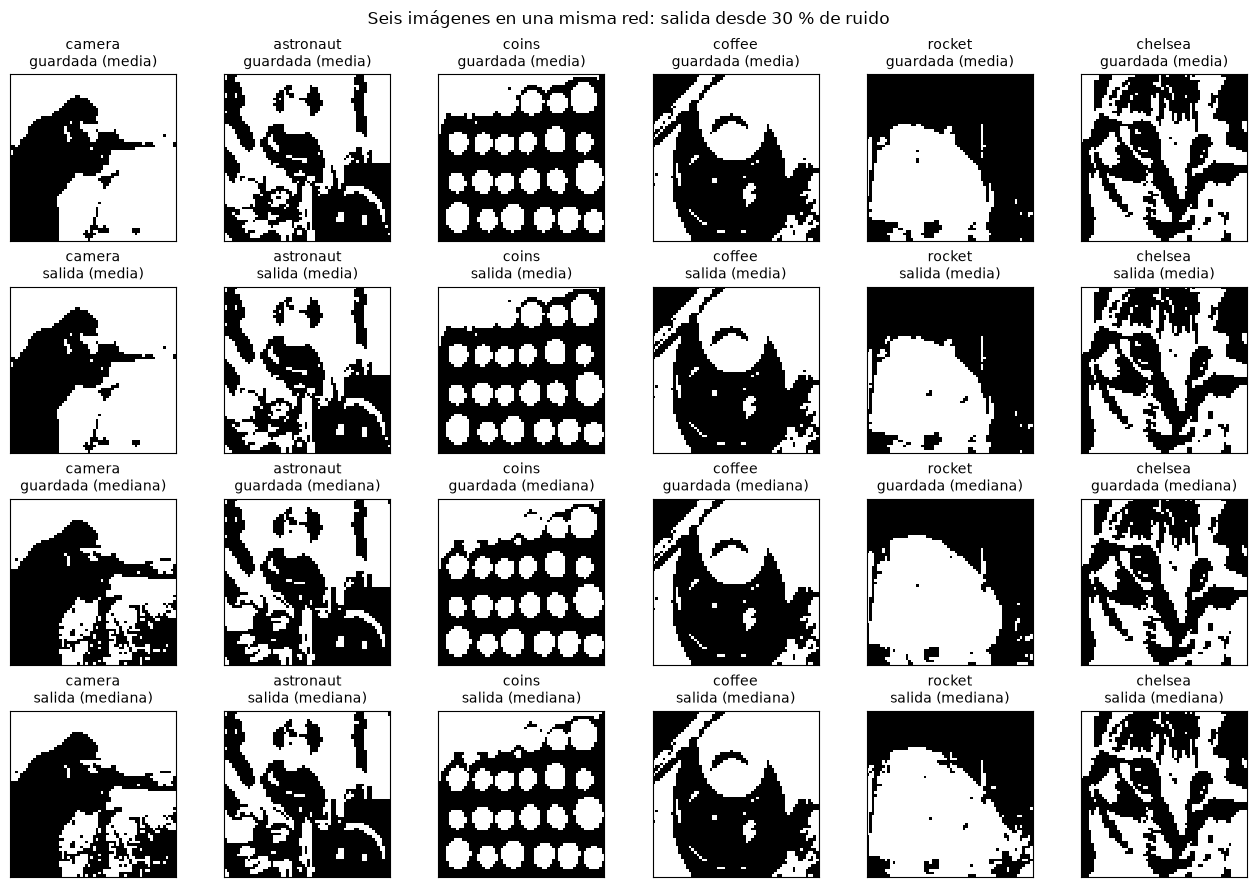

In [28]:
# [Añadido]
filas = [("guardada (media)", conjuntos["umbral media"]), ("salida (media)", finales["umbral media"]),
         ("guardada (mediana)", conjuntos["umbral mediana"]), ("salida (mediana)", finales["umbral mediana"])]
fig, axes = plt.subplots(len(filas), len(NOMBRES_IMG), figsize=(13, 9))
for f, (rotulo, imagenes) in enumerate(filas):
    for c, nombre in enumerate(NOMBRES_IMG):
        mostrar(axes[f, c], imagenes[c], (n, m), f"{nombre}\n{rotulo}")
plt.suptitle("Seis imágenes en una misma red: salida desde 30 % de ruido")
plt.tight_layout()
plt.show()

In [29]:
# [Añadido]
# ¿Cuál imagen falla con seis, y qué pasa al quitar una sola?
for variante in ("umbral media", "umbral mediana"):
    todos = conjuntos[variante]
    C = todos @ todos.T / N
    a, b = np.unravel_index(np.argmax(np.abs(C - np.eye(len(C)))), C.shape)
    print(f"\n{variante}: par más parecido = {NOMBRES_IMG[a]} y {NOMBRES_IMG[b]}, solapamiento {C[a, b]:+.3f}")
    for quitar in [None] + list(range(len(todos))):
        quedan = [k for k in range(len(todos)) if k != quitar]
        X = todos[quedan]
        campos = X @ matriz_pesos(X)
        malos = {NOMBRES_IMG[k]: int(np.sum(c * x < -TOL)) for k, c, x in zip(quedan, campos, X)}
        rotulo = "las seis" if quitar is None else f"sin {NOMBRES_IMG[quitar]}"
        print(f"  {rotulo:15s} píxeles inestables: { {i: j for i, j in malos.items() if j} or 'ninguno'}")


umbral media: par más parecido = camera y rocket, solapamiento -0.460
  las seis        píxeles inestables: {'rocket': 24}
  sin camera      píxeles inestables: ninguno
  sin astronaut   píxeles inestables: ninguno
  sin coins       píxeles inestables: {'rocket': 38}
  sin coffee      píxeles inestables: ninguno
  sin rocket      píxeles inestables: ninguno
  sin chelsea     píxeles inestables: {'rocket': 24}

umbral mediana: par más parecido = camera y rocket, solapamiento -0.459
  las seis        píxeles inestables: {'rocket': 77}
  sin camera      píxeles inestables: ninguno
  sin astronaut   píxeles inestables: {'rocket': 108}
  sin coins       píxeles inestables: {'rocket': 143}
  sin coffee      píxeles inestables: ninguno
  sin rocket      píxeles inestables: ninguno
  sin chelsea     píxeles inestables: {'rocket': 77}


In [30]:
# [Añadido]
# Control que cambia un solo factor: barajar los píxeles de cada imagen por separado
# conserva su cantidad de +1 y -1, y destruye la correlación entre imágenes
rng = np.random.default_rng(SEED)
for variante in ("umbral media", "umbral mediana"):
    X = conjuntos[variante]
    inestables_b, solap_b = [], []
    for _ in range(200):
        Y = np.array([rng.permutation(x) for x in X])
        campos = (Y @ Y.T @ Y - len(Y) * Y) / N          # igual a Y @ W con diagonal nula, sin construir W
        inestables_b.append(np.sum(campos * Y < -TOL))
        solap_b.append(np.abs(Y @ Y.T / N - np.eye(len(Y))).max())
    print(f"{variante}, 200 barajadas: píxeles inestables como máximo {max(inestables_b)} | "
          f"solapamiento como máximo {max(solap_b):.3f}")

    estables_5 = 0
    for quitar in range(len(X)):
        Y = np.delete(X, quitar, axis=0)
        campos = (Y @ Y.T @ Y - len(Y) * Y) / N
        estables_5 += not np.any(campos * Y < -TOL)
    print(f"{variante}, conjuntos de 5 imágenes sin píxeles inestables: {estables_5} de {len(X)}")

umbral media, 200 barajadas: píxeles inestables como máximo 0 | solapamiento como máximo 0.088
umbral media, conjuntos de 5 imágenes sin píxeles inestables: 4 de 6
umbral mediana, 200 barajadas: píxeles inestables como máximo 0 | solapamiento como máximo 0.059
umbral mediana, conjuntos de 5 imágenes sin píxeles inestables: 3 de 6


**Al guardar más imágenes las cuencas de atracción se reducen y algunas memorias dejan de ser exactas.**

Con patrones ortogonales los tres se recuperan siempre hasta 30 % de ruido. En 45 % la recuperación exacta
es 100 % con $P=1$, 65.2 % con $P=2$ y 32.2 % con $P=3$: hay otros atractores compitiendo.

Con imágenes reales el problema aparece mucho antes de lo que sugiere $0.138N$:

- Hasta cuatro imágenes todo funciona. Al entrar la quinta (`rocket`) una memoria se vuelve inestable. Con
  seis, la inestable es `rocket`: 24 píxeles con umbral en la media y 77 con la mediana.
- El desbalance no lo explica, porque con la mediana (mitad de los píxeles en cada valor) también falla.
  La causa es la correlación entre imágenes. Al barajar los píxeles de cada una por separado, que conserva
  su desbalance y solo destruye esa correlación, no queda ni un píxel inestable en 200 repeticiones, con
  los dos umbrales.
- Tampoco se puede culpar solo al par más parecido (`camera` y `rocket`). Quitar `camera` arregla a
  `rocket`, pero quitar `coffee` también, y quitar `coins` la empeora. La interferencia es colectiva: en
  cada píxel se suman los aportes de las demás memorias, que pueden reforzarse o cancelarse.
- No hay un número fijo de imágenes que quepan: de los seis conjuntos de cinco, 4 son estables con la
  media y 3 con la mediana. Depende de cuáles se guarden.
- El daño es pequeño en píxeles (99.9 % correctos con la media y 98.5 % con la mediana, con seis imágenes),
  pero la recuperación ya no es exacta.

### Pregunta 5

> 5. ¿Aparecen estados espurios?

Un estado espurio es un punto fijo que no se guardó. Se prueban las mezclas
$\mathrm{sign}(\pm\xi^1\pm\xi^2\pm\xi^3)$ y además se relaja la red desde 10 000 estados al azar.

In [31]:
# [Añadido]
from itertools import product

# Los 8 candidatos a mezcla: sign(+-xi1 +-xi2 +-xi3)
signos = list(product([1, -1], repeat=3))
mezclas = [np.sign(np.array(c) @ P10) for c in signos]
puntos_fijos = [recuperar(W10, x, np.random.default_rng(SEED))["cambios"] == [0] for x in mezclas]
print(f"mezclas que son puntos fijos: {sum(puntos_fijos)}/{len(mezclas)}")
print("|solapamiento| de las 8 mezclas con cada patrón:", np.unique(np.abs(np.array(mezclas) @ P10.T) / N10))
print(f"energía: patrón = {energia(W10, P10[0]):.1f} | mezcla = {energia(W10, mezclas[0]):.1f}")


def clasificar(s):
    if any(np.array_equal(s, p) for p in P10):
        return "patrón guardado"
    if any(np.array_equal(s, -p) for p in P10):
        return "negativo"
    if any(np.array_equal(s, x) for x in mezclas):
        return "mezcla de tres"
    return "otro"


INICIOS = 10000
rng = np.random.default_rng(SEED)
conteo, distintos = {}, set()
for _ in range(INICIOS):
    r = recuperar(W10, rng.choice([-1.0, 1.0], N10), rng)
    assert r["convergio"]
    tipo = clasificar(r["s"])
    conteo[tipo] = conteo.get(tipo, 0) + 1
    distintos.add(r["s"].tobytes())
print(f"\n{INICIOS} inicios al azar, {len(distintos)} estados finales distintos")
for tipo, c in sorted(conteo.items()):
    print(f"  {tipo:16s} {c:5d} ({c / INICIOS:.1%})")

mezclas que son puntos fijos: 8/8
|solapamiento| de las 8 mezclas con cada patrón: [0.5]
energía: patrón = -48.5 | mezcla = -36.0

10000 inicios al azar, 14 estados finales distintos
  mezcla de tres    1970 (19.7%)
  negativo          4063 (40.6%)
  patrón guardado   3967 (39.7%)


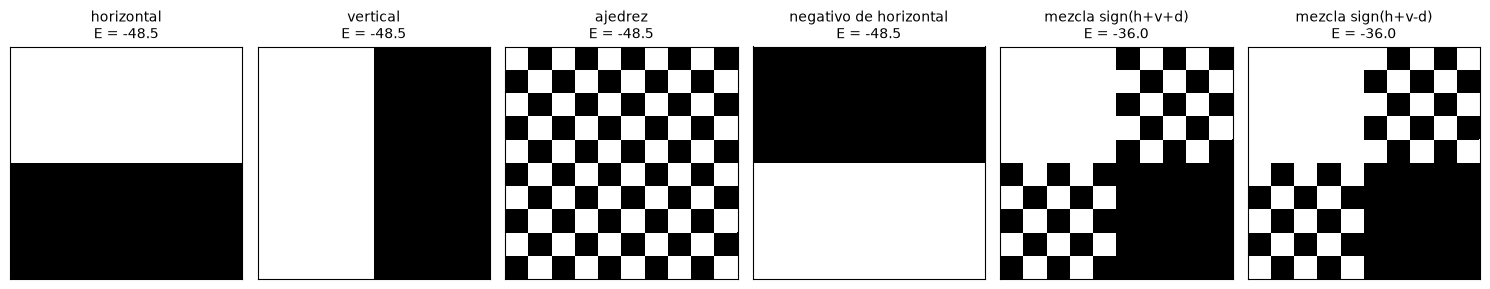

In [32]:
# [Añadido]
muestras = list(P10) + [-P10[0], mezclas[0], mezclas[1]]
titulos = NOMBRES_10 + ["negativo de horizontal", "mezcla sign(h+v+d)", "mezcla sign(h+v-d)"]
fig, axes = plt.subplots(1, len(muestras), figsize=(15, 3.2))
for ax, s, t in zip(axes, muestras, titulos):
    mostrar(ax, s, (10, 10), f"{t}\nE = {energia(W10, s):.1f}")
plt.tight_layout()
plt.show()

**Sí, incluso con solo tres patrones en 100 neuronas.** Los 10 000 inicios terminaron en 14 estados
distintos:

| Tipo | Estados | Inicios que llegan | Energía |
|---|---|---|---|
| Patrones guardados | 3 | 39.7 % | $-48.5$ |
| Negativos | 3 | 40.6 % | $-48.5$ |
| Mezclas de tres | 8 | 19.7 % | $-36.0$ |

Los negativos salen de la simetría $s\to-s$. Las mezclas son mínimos locales: tienen más energía que las
memorias y solapamiento 0.5 en valor absoluto con las tres, pero ningún cambio de un solo píxel las mejora.
Uno de cada cinco inicios al azar queda atrapado en ellas. Se ven como collages de los tres patrones.

### Pregunta 6

> 6. ¿La recuperación depende del orden en que se actualizan los píxeles?

Se fija el estado inicial y se cambia únicamente el orden de visita.

In [33]:
# [Añadido]
ORDENES = 1000
etiquetas = [(f"+{a}", p) for a, p in zip(NOMBRES_10, P10)] + [(f"-{a}", -p) for a, p in zip(NOMBRES_10, P10)]


def nombre_estado(s):
    for e, p in etiquetas:
        if np.array_equal(s, p):
            return e
    for c, x in zip(signos, mezclas):
        if np.array_equal(s, x):
            return "mezcla " + "".join(("+" if a > 0 else "-") + b for a, b in zip(c, "hvd"))
    return "otro"


casos = {
    "un patrón, 25 % de ruido": (matriz_pesos(xi_d), ruidosa_d),
    "tres, ajedrez con 25 %": (W10, agregar_ruido(P10[2], 0.25, seed=10)),
    "tres, ajedrez con 40 %": (W10, agregar_ruido(P10[2], 0.40, seed=10)),
}
for nombre, (W, inicio) in casos.items():
    destinos = {}
    for k in range(ORDENES):
        # mismo inicio en las 1000 corridas: solo cambia el orden de visita
        e = nombre_estado(recuperar(W, inicio, np.random.default_rng(k))["s"])
        destinos[e] = destinos.get(e, 0) + 1
    print(f"{nombre:26s} -> {destinos}")
    if W is W10:
        print("   solapamientos del inicio:", dict(zip(NOMBRES_10, (P10 @ inicio / N10).tolist())))

un patrón, 25 % de ruido   -> {'+ajedrez': 1000}
tres, ajedrez con 25 %     -> {'+ajedrez': 1000}
   solapamientos del inicio: {'horizontal': 0.02, 'vertical': 0.26, 'ajedrez': 0.5}
tres, ajedrez con 40 %     -> {'+vertical': 1000}
   solapamientos del inicio: {'horizontal': -0.04, 'vertical': 0.36, 'ajedrez': 0.2}


inicios cuyo estado final depende del orden: 79.2%
máximo de estados finales distintos desde un mismo inicio: 9


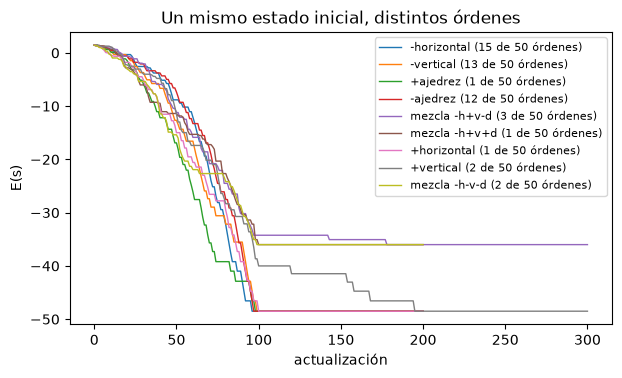

In [34]:
# [Añadido]
# Inicios al azar: cada uno se relaja con 50 órdenes distintos
INICIOS_ORDEN = 500
rng = np.random.default_rng(SEED)
resultados = []
for _ in range(INICIOS_ORDEN):
    inicio = rng.choice([-1.0, 1.0], N10)
    finales_k = [recuperar(W10, inicio, np.random.default_rng(k))["s"] for k in range(50)]
    resultados.append((inicio, finales_k, len({f.tobytes() for f in finales_k})))
n_finales = np.array([r[2] for r in resultados])
print(f"inicios cuyo estado final depende del orden: {np.mean(n_finales > 1):.1%}")
print(f"máximo de estados finales distintos desde un mismo inicio: {n_finales.max()}")

# Se grafica el primer inicio con más destinos, con un orden por cada destino
inicio, finales_k, _ = resultados[n_finales.argmax()]
un_orden, veces = {}, {}
for k, f in enumerate(finales_k):
    un_orden.setdefault(f.tobytes(), k)
    veces[f.tobytes()] = veces.get(f.tobytes(), 0) + 1

plt.figure(figsize=(7, 3.8))
for clave, k in un_orden.items():
    r = recuperar(W10, inicio, np.random.default_rng(k))
    plt.plot(r["E"], lw=1, label=f"{nombre_estado(r['s'])} ({veces[clave]} de 50 órdenes)")
plt.xlabel("actualización")
plt.ylabel("E(s)")
plt.title("Un mismo estado inicial, distintos órdenes")
plt.legend(fontsize=8)
plt.show()

In [35]:
# [Añadido]
# Lo anterior usa un inicio por caso. Ahora, 200 inicios por nivel de ruido, cada uno con 20 órdenes
rng = np.random.default_rng(SEED)
for j, p in enumerate((0.25, 0.30, 0.35, 0.40, 0.45)):
    dependen = 0
    for k in range(200):
        inicio = agregar_ruido(P10[k % 3], p, seed=1000 * j + k)
        destinos = {recuperar(W10, inicio, np.random.default_rng(o))["s"].tobytes() for o in range(20)}
        dependen += len(destinos) > 1
    print(f"tres patrones, ruido {p:.0%}: el orden cambia el estado final en {dependen / 200:.1%} de los inicios")

tres patrones, ruido 25%: el orden cambia el estado final en 0.5% de los inicios
tres patrones, ruido 30%: el orden cambia el estado final en 0.0% de los inicios
tres patrones, ruido 35%: el orden cambia el estado final en 12.0% de los inicios
tres patrones, ruido 40%: el orden cambia el estado final en 43.0% de los inicios
tres patrones, ruido 45%: el orden cambia el estado final en 81.0% de los inicios


**Sí puede depender, y más cuanto más lejos empiece la red de una memoria.**

- Con un solo patrón y 25 % de ruido los 1 000 órdenes llegan al tablero.
- Con tres patrones el efecto crece con el ruido: el orden cambia el final en el 0.5 % de los
  inicios con 25 % de ruido, en 0.0 % con 30 %, 12.0 % con 35 %, 43.0 % con 40 % y 81.0 % con 45 %. Con
  poco ruido es casi indiferente, y cerca del 50 % decide el resultado.
- Un inicio aislado puede engañar. En el ejemplo de 40 % los 1 000 órdenes llegan a `vertical`, porque ese
  ruido dejó la entrada más cerca de `vertical` (0.36) que del tablero (0.20). Ahí el orden no influye, pero
  eso no vale para todos los inicios de ese nivel.
- Desde estados al azar el efecto es grande: en el 79.2 % el estado final cambió con el orden, y un mismo
  inicio llegó a 9 estados distintos. La gráfica muestra ese caso. Todas las trayectorias bajan, pero a
  mínimos diferentes.

### Pregunta 7

> 7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

En la sincrónica todas las neuronas cambian a la vez con el campo del estado anterior. Se comparan ambas
desde los mismos inicios, en tres redes de 100 neuronas.

In [36]:
# [Añadido]
def recuperar_sincronica(W, s0, max_pasos=100):
    """Todas las neuronas se actualizan a la vez con el campo del estado anterior."""
    s = np.array(s0, dtype=float)
    previo, E = None, [energia(W, s)]
    for _ in range(max_pasos):
        campo = W @ s
        nuevo = np.where(campo > TOL, 1.0, np.where(campo < -TOL, -1.0, s))
        if np.array_equal(nuevo, s):
            return s, np.array(E), "punto fijo"
        E.append(energia(W, nuevo))
        if previo is not None and np.array_equal(nuevo, previo):
            return nuevo, np.array(E), "ciclo de 2"
        previo, s = s, nuevo
    return s, np.array(E), "sin converger"


ENSAYOS = 2000
rng_pat, rng = np.random.default_rng(SEED), np.random.default_rng(SEED + 1)
redes = [("3 ortogonales", P10), ("5 al azar", rng_pat.choice([-1.0, 1.0], (5, N10))),
         ("15 al azar", rng_pat.choice([-1.0, 1.0], (15, N10)))]
ejemplo = None
print(f"{'red':15s} {'inicio':10s} | {'sinc: ciclo':>11} {'E sube':>7} {'exacta':>7} | "
      f"{'asinc: p. fijo':>14} {'E sube':>7} {'exacta':>7}")
for nombre, X in redes:
    W = matriz_pesos(X)
    for tipo, frac in (("ruido 20 %", 0.20), ("al azar", None)):
        c = dict.fromkeys(["ciclo", "sube_s", "ok_s", "fijo", "sube_a", "ok_a"], 0)
        for k in range(ENSAYOS):
            obj = X[k % len(X)]
            ini = rng.choice([-1.0, 1.0], N10) if frac is None else agregar_ruido(obj, frac, seed=k)
            ss, Es, estado = recuperar_sincronica(W, ini)
            ra = recuperar(W, ini, rng)
            sube = np.any(np.diff(Es) > 1e-9)
            c["ciclo"] += estado == "ciclo de 2"
            c["sube_s"] += sube
            c["fijo"] += ra["convergio"]
            c["sube_a"] += np.any(np.diff(ra["E"]) > 1e-9)
            c["ok_s"] += np.array_equal(ss, obj)
            c["ok_a"] += np.array_equal(ra["s"], obj)
            if ejemplo is None and sube and estado == "ciclo de 2":
                ejemplo = (nombre, tipo, W, ini, Es, ra["E"])
        f = {a: f"{b / ENSAYOS:.1%}" for a, b in c.items()}
        if frac is None:
            f["ok_s"] = f["ok_a"] = "-"      # sin objetivo no hay recuperación que medir
        print(f"{nombre:15s} {tipo:10s} | {f['ciclo']:>11} {f['sube_s']:>7} {f['ok_s']:>7} | "
              f"{f['fijo']:>14} {f['sube_a']:>7} {f['ok_a']:>7}")

red             inicio     | sinc: ciclo  E sube  exacta | asinc: p. fijo  E sube  exacta
3 ortogonales   ruido 20 % |        0.0%    0.0%  100.0% |         100.0%    0.0%  100.0%
3 ortogonales   al azar    |        5.7%    0.0%       - |         100.0%    0.0%       -
5 al azar       ruido 20 % |        0.0%    0.0%  100.0% |         100.0%    0.0%  100.0%
5 al azar       al azar    |        0.8%    0.0%       - |         100.0%    0.0%       -
15 al azar      ruido 20 % |       16.4%   12.6%   21.1% |         100.0%    0.0%   22.3%
15 al azar      al azar    |       11.8%   14.3%       - |         100.0%    0.0%       -


solapamiento inicial: 0.0
sincrónica: ciclo de 2 | energías: [0.5 0.5 0.5] | solapamiento: 0.0
asincrónica: solapamiento final = -1.0

ejemplo de la gráfica (15 al azar, inicio ruido 20 %): energías sincrónicas = [-18.06 -43.02 -44.3  -44.54 -44.3  -45.1  -48.62 -50.2  -50.6  -50.76
 -50.76 -50.76]
energía final asincrónica desde ese mismo inicio = -46.94


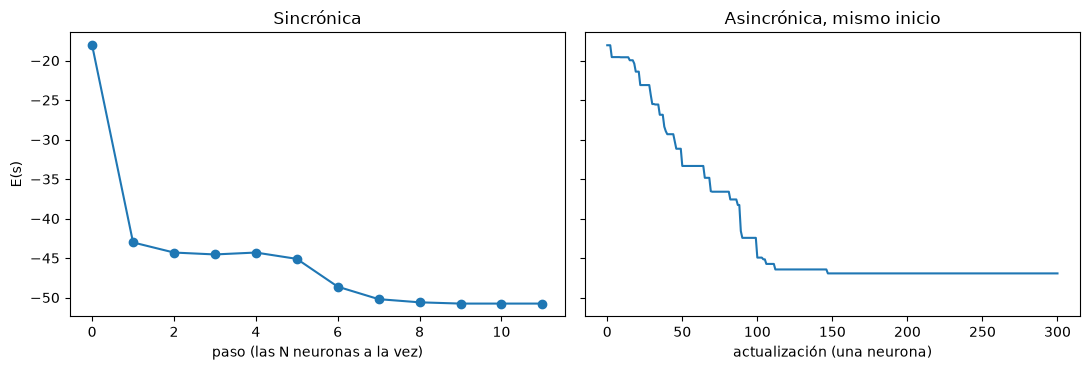

In [37]:
# [Añadido]
# Caso extremo: un patrón y un inicio con exactamente la mitad de los píxeles invertidos
mitad = agregar_ruido(xi_d, 0.5, seed=SEED)
W_d = matriz_pesos(xi_d)
ss, Es, estado = recuperar_sincronica(W_d, mitad)
sa = recuperar(W_d, mitad, np.random.default_rng(SEED))["s"]
print("solapamiento inicial:", mitad @ xi_d / N10)
print("sincrónica:", estado, "| energías:", Es.round(2), "| solapamiento:", ss @ xi_d / N10)
print("asincrónica: solapamiento final =", sa @ xi_d / N10)

nombre, tipo, W, ini, Es, Ea = ejemplo
print(f"\nejemplo de la gráfica ({nombre}, inicio {tipo}): energías sincrónicas = {Es.round(2)}")
print(f"energía final asincrónica desde ese mismo inicio = {Ea[-1]:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
axes[0].plot(Es, "o-")
axes[0].set(title="Sincrónica", xlabel="paso (las N neuronas a la vez)", ylabel="E(s)")
axes[1].plot(Ea)
axes[1].set(title="Asincrónica, mismo inicio", xlabel="actualización (una neurona)")
plt.tight_layout()
plt.show()

In [38]:
# [Añadido]
# La tabla usa una sola red de 15 patrones. La recuperación exacta se repite en 100 redes distintas
rng = np.random.default_rng(SEED)
exacta_s = exacta_a = total = 0
for r in range(100):
    X = rng.choice([-1.0, 1.0], (15, N10))
    W = matriz_pesos(X)
    for k in range(100):
        obj = X[k % len(X)]
        ini = agregar_ruido(obj, 0.20, seed=100 * r + k)
        exacta_s += np.array_equal(recuperar_sincronica(W, ini)[0], obj)
        exacta_a += np.array_equal(recuperar(W, ini, rng)["s"], obj)
        total += 1
print(f"100 redes de 15 patrones, 20 % de ruido: recuperación exacta sincrónica {exacta_s / total:.1%}, "
      f"asincrónica {exacta_a / total:.1%}")

100 redes de 15 patrones, 20 % de ruido: recuperación exacta sincrónica 48.5%, asincrónica 46.7%


**La asincrónica garantiza que la energía no sube y que se llega a un punto fijo. La sincrónica no
garantiza ninguna de las dos cosas.**

- La asincrónica llegó a un punto fijo en el 100 % de los ensayos y su energía no subió en ninguno.
- La sincrónica puede quedar alternando entre dos estados. Le pasó al 5.7 % de los inicios al azar con
  tres patrones ortogonales y al 16.4 % de los inicios con ruido en la red de 15 patrones. En esta última
  la energía subió en algún paso en el 12.6 % de los ensayos con ruido: $\Delta E=-2|h_i|$ solo vale si
  cambia una neurona a la vez.
- El caso extremo es un patrón con $q=0$. Todas las neuronas ven $h_i=-s_i/N$, se invierten juntas, $q$
  sigue en 0 y el ciclo no termina, con energía 0.5. La asincrónica rompe el empate con el primer cambio.
- Que la energía baje siempre no significa que baje más. En el ejemplo graficado la asincrónica termina
  en $-46.94$ y la sincrónica oscila entre estados de $-50.76$.
- En calidad de recuperación casi no difieren. Con pocos patrones las dos llegan al 100 %. Con 15, en el
  promedio de 100 redes, la sincrónica recupera 48.5 % y la asincrónica 46.7 %. La red de la tabla resultó más difícil que el promedio (21.1 % y
  22.3 %). La ventaja práctica de la sincrónica es que cada paso es un solo producto $Ws$, fácil de
  paralelizar.

# Capacidad de memoria

> $$
> P_c \approx 0.138N
> $$
>
> Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.

Para cada $N$ y $\alpha=P/N$ se generan redes con patrones aleatorios y se arranca en las propias memorias,
sin ruido. Se miden el solapamiento final y la fracción de memorias que quedan sin ningún error.

El error de un paso se puede predecir. En una memoria, $Nh_i\xi_i$ es una señal $N-1$ más una suma de
$(N-1)(P-1)$ términos $\pm1$. Aproximándola por una gaussiana, la probabilidad de que un píxel sea
inestable es

$$P_{\rm error}=\Phi\!\left(-\sqrt{\frac{N-1}{P-1}}\right).$$

In [39]:
# [Añadido]
from scipy.stats import norm

alfas = [0.02, 0.05, 0.08, 0.10, 0.12, 0.138, 0.16, 0.20, 0.25]
tamanos = {100: 80, 300: 30, 1000: 20}        # N: número de redes independientes
rng = np.random.default_rng(SEED)
capacidad = {}
print(f"{'N':>5} {'alfa':>6} {'P':>4} {'error 1 paso':>13} {'teoría':>8} {'solap. final':>13} {'exactos':>8}")
for N_c, redes_c in tamanos.items():
    filas = []
    for a in alfas:
        P = max(1, round(a * N_c))
        error1, solap, exactos = [], [], []
        for _ in range(redes_c):
            X = rng.choice([-1.0, 1.0], (P, N_c))
            W = matriz_pesos(X)
            error1.append(np.mean((X @ W) * X < -TOL))
            for mu in range(min(P, 5)):       # se parte de cada patrón, sin ruido
                s = recuperar(W, X[mu], rng)["s"]
                solap.append(s @ X[mu] / N_c)
                exactos.append(np.array_equal(s, X[mu]))
        teoria = norm.sf(np.sqrt((N_c - 1) / (P - 1))) if P > 1 else 0.0
        filas.append((P / N_c, np.mean(solap), np.mean(exactos)))
        print(f"{N_c:5d} {P / N_c:6.3f} {P:4d} {np.mean(error1):13.4f} {teoria:8.4f} "
              f"{np.mean(solap):13.3f} {np.mean(exactos):8.1%}")
    capacidad[N_c] = np.array(filas)

    N   alfa    P  error 1 paso   teoría  solap. final  exactos
  100  0.020    2        0.0000   0.0000         1.000   100.0%
  100  0.050    5        0.0000   0.0000         1.000   100.0%
  100  0.080    8        0.0001   0.0001         1.000    99.5%
  100  0.100   10        0.0004   0.0005         0.997    96.8%
  100  0.120   12        0.0015   0.0013         0.990    86.8%
  100  0.140   14        0.0025   0.0029         0.975    79.8%
  100  0.160   16        0.0046   0.0051         0.954    67.2%
  100  0.200   20        0.0112   0.0112         0.884    43.2%
  100  0.250   25        0.0208   0.0211         0.721    17.0%
  300  0.020    6        0.0000   0.0000         1.000   100.0%
  300  0.050   15        0.0000   0.0000         1.000   100.0%
  300  0.080   24        0.0001   0.0002         1.000    96.0%
  300  0.100   30        0.0005   0.0007         0.999    88.0%
  300  0.120   36        0.0015   0.0017         0.992    65.3%
  300  0.137   41        0.0031   0.0031

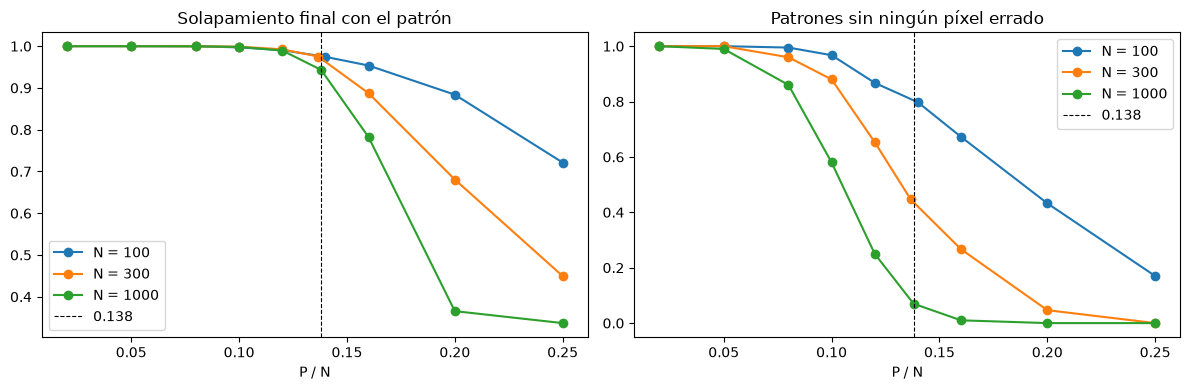

N =  100: 0.138 N =   13.8 | N / (2 ln N) =   10.9
N =  300: 0.138 N =   41.4 | N / (2 ln N) =   26.3
N = 1000: 0.138 N =  138.0 | N / (2 ln N) =   72.4
N = 4096: 0.138 N =  565.2 | N / (2 ln N) =  246.2


In [40]:
# [Añadido]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for N_c, f in capacidad.items():
    axes[0].plot(f[:, 0], f[:, 1], "o-", label=f"N = {N_c}")
    axes[1].plot(f[:, 0], f[:, 2], "o-", label=f"N = {N_c}")
for ax, titulo in zip(axes, ["Solapamiento final con el patrón", "Patrones sin ningún píxel errado"]):
    ax.axvline(0.138, color="k", ls="--", lw=0.8, label="0.138")
    ax.set(xlabel="P / N", title=titulo)
    ax.legend()
plt.tight_layout()
plt.show()

for N_c in (100, 300, 1000, 4096):
    print(f"N = {N_c:4d}: 0.138 N = {0.138 * N_c:6.1f} | N / (2 ln N) = {N_c / (2 * np.log(N_c)):6.1f}")

**El límite $0.138N$ corresponde a recordar bien, no a recordar sin errores.**

- El error de un paso medido sigue la teoría gaussiana en los tres tamaños.
- Con $N=1000$ y $\alpha=0.138$ solo 0.34 % de los píxeles es inestable en el primer paso y el solapamiento
  final todavía es 0.943. Pero apenas el 7 % de las memorias queda exacta.
- Por encima del límite esos pocos errores desencadenan otros: con $N=1000$ el solapamiento final cae a
  0.782 en $\alpha=0.16$ y a 0.366 en $\alpha=0.20$. La caída es más brusca cuanto mayor es $N$. El valor
  0.138 es un resultado para $N$ grande, y con $N=100$ la transición es muy suave.
- Si se exige recuperación exacta hace falta $NP_{\rm error}\ll1$. Con la cola gaussiana
  $e^{-1/(2\alpha)}$ eso da una escala $P\sim N/(2\ln N)$, bastante menor: para $N=4096$ son 246.2
  patrones en lugar de 565.2.
- La frase del enunciado es aproximada en dos sentidos: los errores aparecen antes del límite y los
  espurios también (pregunta 5, con $P=3$). Además, el límite supone patrones independientes. Con
  imágenes, algunos conjuntos de solo cinco ya fallan en una red cuyo límite nominal es 565 (pregunta 4).

## Conclusiones

1. **Memoria asociativa.** Con una imagen guardada la recuperación es exacta para cualquier ruido menor que
   50 %. Por encima se obtiene el negativo, que tiene la misma energía.
2. **Energía.** Con actualización asincrónica nunca aumenta, y por eso la red converge a un mínimo local.
3. **Varios patrones.** Las cuencas se reducen y aparecen espurios: con tres patrones ortogonales, 19.7 %
   de los inicios al azar termina en una mezcla.
4. **Orden y tipo de actualización.** La influencia del orden crece al alejarse de las memorias. La
   actualización sincrónica puede entrar en ciclos y subir la energía, aunque recupera parecido.
5. **Capacidad.** El valor $0.138N$ vale para patrones aleatorios y tolera algunos píxeles errados. Con
   imágenes correlacionadas puede fallar muchísimo antes, según cuáles se guarden.

#### Reproducibilidad

In [41]:
# [Añadido]
import sys
import matplotlib
import scipy
import skimage

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| scikit-image", skimage.__version__)

Python 3.14.7 | numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2 | scikit-image 0.26.0


Todos los sorteos tienen semilla fija (`SEED = 42`, más las que fija el enunciado), y una nueva ejecución
reproduce las mismas cifras. El notebook tarda entre 5 y 7 minutos en CPU en este equipo, sobre todo por
las repeticiones de las preguntas y de la capacidad. No descarga datos: las imágenes vienen con
scikit-image.